In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot
from scipy.stats import binom
print(np.__version__)

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay
from sklearn.calibration import calibration_curve
import seaborn

import os
import sys
if '../../lib/' not in sys.path:
    sys.path.append('../../lib/')
import dio3
import multi_fgl_utils as util
import plot_util as putil

1.24.3


In [2]:
if 1:
    import importlib
    importlib.reload(util);


In [3]:
def get_descr_str(llat_ROI, hlat_ROI, cdict={}, bmask=10, output_text=False):
    feature_mode = cdict.get('features', '')
    if output_text:
        res = cdict.get('cat_name', '4FGL-DR4')
        if feature_mode.find('Toby') > -1:
            res += ' Toby'
        if npar == 1:
            res += ' const prior'
        else:
            res += ' %s prior, %i params' % (mdl_func.__name__, npar)
        if llat_ROI:
            res += r', $|b| < %i^\circ$' % bmask
        if hlat_ROI:
            res += r', $|b| > %i^\circ$' % bmask
        return res
    res = cdict.get('case', '4FGL-DR4')
    if feature_mode.find('Toby') > -1:
        res += ' Toby'
    if llat_ROI:
        res += '_unas_below_b%i' % bmask
    if hlat_ROI:
        res += '_unas_above_b%i' % bmask
    return res


In [4]:
script_fn = 'fermi_multiclass/notebooks/SGU/cat2gu.ipynb'
fig_meta = {'Author': 'Dmitry Malyshev', 'Subject': script_fn}

# select the catalog and the case
cat_name = '4FGL-DR4' # '4FGL_DR3'
folder_out = None
if cat_name == '4FGL-DR4':
    baseline_case = '4FGL-DR4_GMM_RF'
    #case = '4FGL-DR4_GMM_RF'
    #case = '4FGL-DR4_GMM_RF_no_bcu_spp'
    #case = '4FGL-DR4_GMM_RF_no_bcu'
    #case = '4FGL-DR4_GMM_RF_no_coord'
    case = '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp'
    #case = '4FGL-DR4_GMM_RF_no_coord_no_bcu'
    #case = '4FGL-DR4_GMM_PDF_pshift_nGauss1_npar4'
    #case = '4FGL-DR4_GMM_PDF_no_coord_pshift_nGauss1_npar4'
    #case = '4FGL-DR4_GMM_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4'

    #baseline_case = '4FGL-DR4_2class_RF' # '4FGL-DR4_GMM_RF', '4FGL-DR4_2class_RF'
    #case = '4FGL-DR4_2class_pulsars_AGNs'
    #case = '4FGL-DR4_GMM_RF'
    #baseline_case = '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp'
    #case = '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp'
    #baseline_case = '4FGL-DR4_GMM_RF_no_coord'
    #case = '4FGL-DR4_GMM_RF_no_coord'
    #case = '4FGL-DR4_GMM_RF_no_coord_w'
if cat_name == '4FGL-DR3':
    #baseline_case = '4FGL-DR3_GMM_RF_no_coord_no_bcu_spp'
    #case = '4FGL-DR3_GMM_RF_no_coord_no_bcu_spp_nmin50' # '4FGL-DR4_GMM_RF_no_prune'
    baseline_case = '4FGL-DR3_3class_RF'
    #case = '4FGL-DR3_3class_RF'
    #case = '4FGL-DR3_3class_spec_features_RF'
    baseline_case = '4FGL-DR3_3class_Toby'
    case = '4FGL-DR3_3class_Toby' # '4FGL_DR4_2class', '4FGL_DR4_RF_RF'


baseline = (case == baseline_case)
root_folder = '../../'
config_folder = root_folder + 'config/'

# generic inputs
cdict = util.get_config_dict(cat_name=cat_name, 
                             baseline_case=baseline_case, 
                             case=case, 
                             folder=config_folder)

cdict['root_folder'] = root_folder
#folder_in = cdict['root_folder'] + cdict.get('folder_in', 'data_in/')
#folder_out = cdict['root_folder'] + cdict.get('folder_out', 'data_out/')
#folder = folder_out
Eind = int(cdict.get('Eind', 1000))
class_name = cdict.get('class_name', 'CLASS1')

assoc_sources = cdict.get('assoc_sources', 'all_assoc')
sep_model = cdict.get('sep_model', 'GMM')
#sep_model = 'RF' # 'GMM', 'RF'
nmin = cdict.get('nmin')
if nmin is not None: 
    nmin = int(nmin)
max_depth = int(cdict.get('max_depth', 5))
feature_mode = cdict.get('features', 'all_features')

alg = cdict.get('class_alg', 'RF')
train_weighting = cdict.get('train_weighting')
test_weighting = cdict.get('test_weighting')
weighted = (train_weighting is not None) #or (test_weighting is not None)
#oversample_factor = 1 # used for 'resampled' training and testing
max_sample = int(cdict.get('max_sample', 7))
test_frac = float(cdict.get('test_frac', 0.3))
nav = int(cdict.get('nav', 10))


tree_alg = cdict.get('sep_model', 'GMM')
#tree_alg = 'RF' # 'stat', 'GMM', 'RF', '4class', '2class', 'RF_aakash'


# input data
tree_cat_fn = util.get_tree_cat_fn(cdict)
tree_cat_dict = dio3.loaddict(tree_cat_fn)
if util.exist_internal(tree_cat_dict):
    util.remove_internal(tree_cat_dict)
cat_tree = list(tree_cat_dict.keys())
nclasses = len(tree_cat_dict)
max_tree_cat_dict = util.tree2max_tree(tree_cat_dict)
dec_tree_cat_dict = util.max_tree2dec_tree(max_tree_cat_dict)
nodes = [str(key) for key in dec_tree_cat_dict.keys()]


xdf_fn = util.get_xdf_fn(cdict)
xdf = pd.read_csv(xdf_fn, index_col=0)
ns = len(xdf)

all_features = [name for name in xdf.columns if name.find('CLASS') == -1]
if feature_mode == 'all_features':
    features = all_features
elif feature_mode == 'no_coord_features':
    features = [feat for feat in all_features if feat.find('GL') == -1]


nsrc_dict = util.get_nsrc_dict(xdf, class_column=class_name, classes='associated')
nsrc_df = util.nsrc_dict2df(nsrc_dict)
#assoc_classes = list(nsrc_dict.keys())
assoc_classes = []
for cls in dec_tree_cat_dict.values():
    assoc_classes.extend(cls)
all_classes = list(set(xdf[class_name]))
unas_classes = [cl for cl in all_classes if cl not in assoc_classes]
unas_order = ['unas', 'unk', 'bcu', 'spp']
ucls = []
for cl in unas_order:
    if cl in unas_classes:
        unas_classes.remove(cl)
        ucls.append(cl)
ucls.extend(unas_classes)
unas_classes = ucls
print(unas_classes)

add_pshift = int(cdict.get('prior_shift', 0))
folder_out = '%sresults/%s_probabilistic_catalogs/' % (root_folder, util.get_cat_descr(cdict, add_pshift=0))
fn = '%s%s_%s' % (folder_out, util.get_cat_descr(cdict, add_pshift=add_pshift), 'prob_cat.csv')


#folder_out = '../results/%s_probabilistic_classification_weighted/' % cat_name
#fn = folder_out + util.get_cat_descr(cdict)
summary_fn = fn.replace('prob_cat.csv', 'summary.csv')

unas_key = ''
for cl in unas_classes:
    unas_key += '%s,' % cl
unas_key = unas_key[:-1]
print(unas_key)

cat_df = pd.read_csv(fn, index_col=0)
sum_df = pd.read_csv(summary_fn, index_col=0)
if case.find('Toby') > -1:
    cat_df['CLASS1'] = ['%s' %s.split('-')[0] for s in cat_df['source_type']]
    unas_mask = cat_df['CLASS1'] == 'unid'
    cat_df['CLASS1'][unas_mask] = 'unas'
    algs = [cdict['class_alg']]
    for node in nodes:
        for alg in algs:
            cl = '%s_%s' % (node, alg)
            cat_df[cl + '_std'] = 0.01 * cat_df[cl] # hack/placeholder

    nmax = len(xdf.index[0])
    xdf.index = [x[:17] for x in xdf.index]
    xdf = xdf.loc[cat_df.index]
else:
    algs = ['RF', 'NN']
unas_mask = (cat_df['CLASS1'] == 'unas') | (cat_df['CLASS1'] == 'unk')
for cls in tree_cat_dict.values():
    assoc_classes.extend(cls)
amask_all = util.get_cl_mask(assoc_classes, cat_df, cname=class_name)

ns = len(cat_df)

['unas', 'unk', 'bcu', 'spp']
unas,unk,bcu,spp


In [5]:
hlat_ROI = 0
llat_ROI = 1
if hlat_ROI:
    bmask = 10
    hmask = np.abs(xdf['sin(GLAT)']) > np.sin(np.deg2rad(bmask)) # select high latitudes
    #xdf = xdf[hmask]
    ROI_name = 'High lat'
    ROI_fn_str = 'egal'
elif llat_ROI:
    bmask = 10
    hmask = np.abs(xdf['sin(GLAT)']) < np.sin(np.deg2rad(bmask)) # select low latitudes
    #xdf = xdf[hmask]
    ROI_name = 'Low lat'
    ROI_fn_str = 'gal'
else:
    hmask = np.ones(ns, dtype=bool)
    ROI_name = 'All sky'
    ROI_fn_str = 'all'
    bmask = None
ngu = sum(unas_mask & hmask)
nga = sum(amask_all & hmask)

In [6]:
save_plots = 1
save_png = 1
descr_str = get_descr_str(llat_ROI, hlat_ROI, cdict=cdict, bmask=bmask)
plots_folder = '../../plots/SGU/%s/' % descr_str
if not os.path.isdir(plots_folder):
    print('Make folder')
    os.makedirs(plots_folder)
print(plots_folder)
print(descr_str)

../../plots/SGU/4FGL-DR4_GMM_RF_no_coord_no_bcu_spp_unas_below_b10/
4FGL-DR4_GMM_RF_no_coord_no_bcu_spp_unas_below_b10


In [7]:
sum_df

,Class label,Node,Physical classes,N assoc,RF assoc,NN assoc,"RF unas,unk,bcu,spp","NN unas,unk,bcu,spp"
Group,,,,,,,,
1,fsrq+,0,"fsrq, nlsy1, css",833,839.0 +- 3.0,836.4 +- 1.7,1158.7 +- 4.5,1275.2 +- 3.1
2,bll+,1,"bll, sey, sbg, agn, ssrq, rdg",1565,1567.8 +- 3.1,1568.2 +- 1.8,1791.6 +- 4.5,1822.4 +- 2.6
3,psr+,10,"snr, hmb, nov, pwn, psr, gc",225,213.9 +- 1.7,218.1 +- 2.3,576.7 +- 3.6,469.3 +- 3.7
4,msp+,11,"msp, lmb, glc, gal, sfr, bin",244,246.2 +- 2.0,244.3 +- 2.0,797.0 +- 4.1,757.0 +- 3.1


In [9]:
alg = cdict['class_alg']
if 'Gauss' in list(sum_df['Class label']):
    gdict = {sum_df.index[-1]:'Gauss'}
else:
    gdict = {}
pgu = np.array([cat_df['%s_%s' % (gdict.get(i, i), alg)][unas_mask & hmask] for i in sum_df.index])
pga = np.array([cat_df['%s_%s' % (gdict.get(i, i), alg)][amask_all & hmask] for i in sum_df.index])

In [10]:
psum = [np.sum(pgu[i-1]) for i in sum_df.index]
psuma = [np.sum(pga[i-1]) for i in sum_df.index]
psum_sorted = np.sort(psum)[::-1]
ind_sort = [psum.index(v) for v in psum_sorted]

In [11]:
sum_df

,Class label,Node,Physical classes,N assoc,RF assoc,NN assoc,"RF unas,unk,bcu,spp","NN unas,unk,bcu,spp"
Group,,,,,,,,
1,fsrq+,0,"fsrq, nlsy1, css",833,839.0 +- 3.0,836.4 +- 1.7,1158.7 +- 4.5,1275.2 +- 3.1
2,bll+,1,"bll, sey, sbg, agn, ssrq, rdg",1565,1567.8 +- 3.1,1568.2 +- 1.8,1791.6 +- 4.5,1822.4 +- 2.6
3,psr+,10,"snr, hmb, nov, pwn, psr, gc",225,213.9 +- 1.7,218.1 +- 2.3,576.7 +- 3.6,469.3 +- 3.7
4,msp+,11,"msp, lmb, glc, gal, sfr, bin",244,246.2 +- 2.0,244.3 +- 2.0,797.0 +- 4.1,757.0 +- 3.1


In [12]:
for i in sum_df.index:
    print('%s: %s' % (sum_df['Class label'][i], sum_df['Physical classes'][i]))

fsrq+: fsrq, nlsy1, css
bll+: bll, sey, sbg, agn, ssrq, rdg
psr+: snr, hmb, nov, pwn, psr, gc
msp+: msp, lmb, glc, gal, sfr, bin


save figure to file: ../../plots/SGU/4FGL-DR4_GMM_RF_no_coord_no_bcu_spp_unas_below_b10//mclass_gal_unas_class_p_hist_4FGL-DR4_GMM_RF_no_coord_no_bcu_spp_unas_below_b10.pdf
save figure to file: ../../plots/SGU/4FGL-DR4_GMM_RF_no_coord_no_bcu_spp_unas_below_b10//mclass_gal_assoc_class_p_hist_4FGL-DR4_GMM_RF_no_coord_no_bcu_spp_unas_below_b10.pdf


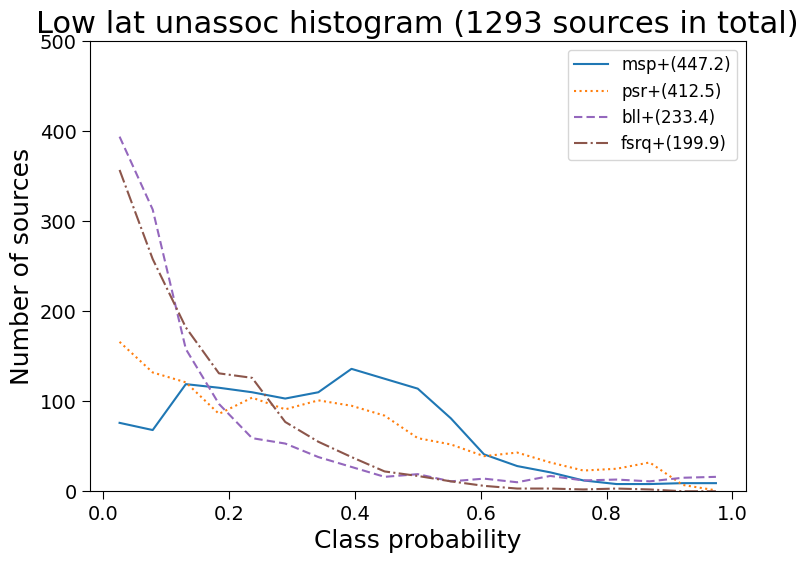

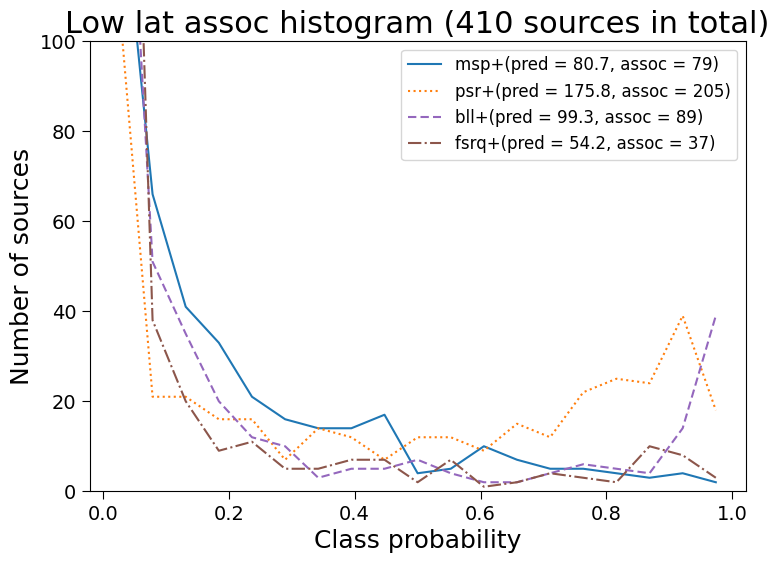

In [13]:
pars_dict={'legend.fontsize': 12}
putil.setup_figure_pars(pars_dict)

lss_dict = {'msp+': '-', 
            'psr+': ':', 
            'bcu+': (0, (4, 2, 1, 1, 1, 2)), 
            'spp+': (0, (7, 3)),
            'bll+': (0, (4, 2)), 
            'fsrq+': '-.', 
            'Gauss':(0, (1, 3)),
           }

colors = pyplot.rcParams['axes.prop_cycle'].by_key()['color']
c_dict = {cl:colors[i] for i, cl in enumerate(lss_dict.keys())}

bins = np.linspace(0, 1, 20)
xc = (bins[1:] + bins[:-1]) / 2.


pyplot.figure()
for i in ind_sort:
    cl = sum_df['Class label'].iloc[i]
    if np.sum(pgu[i]) > 2.:
        y, xb = np.histogram(pgu[i], bins=bins)
        label = cl + '(%.1f)' % psum[i]
        pyplot.plot(xc, y, ls=lss_dict[cl], c=c_dict[cl], label=label)

pyplot.legend()
pyplot.ylim(0, 500)
pyplot.xlabel('Class probability')
pyplot.ylabel('Number of sources')
pyplot.title('%s unassoc histogram (%i sources in total)' % (ROI_name, ngu))


if save_plots:
    fn = '%s/mclass_%s_unas_class_p_hist_%s.pdf' % (plots_folder, ROI_fn_str, descr_str)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    if save_png:
        fn = fn.replace('.pdf', '.png')
        pyplot.savefig(fn, metadata=fig_meta)

pyplot.figure()
for i in ind_sort:
    cl = sum_df['Class label'].iloc[i]
    if 1:
        cls = sum_df['Physical classes'].iloc[i].split(', ')
        amask = util.get_cl_mask(cls, cat_df, cname=class_name) & hmask
        na_cl = sum(amask)
    y, xb = np.histogram(pga[i], bins=bins)
    label = cl + '(pred = %.1f, assoc = %i)' % (psuma[i], na_cl)
    pyplot.plot(xc, y, ls=lss_dict[cl], c=c_dict[cl], label=label)

pyplot.legend()
pyplot.ylim(0, 100)
pyplot.xlabel('Class probability')
pyplot.ylabel('Number of sources')
pyplot.title('%s assoc histogram (%i sources in total)' % (ROI_name, nga))

if save_plots:
    fn = '%s/mclass_%s_assoc_class_p_hist_%s.pdf' % (plots_folder, ROI_fn_str, descr_str)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    if save_png:
        fn = fn.replace('.pdf', '.png')
        pyplot.savefig(fn, metadata=fig_meta)


save figure to file: ../../plots/SGU/4FGL-DR4_GMM_RF_no_coord_no_bcu_spp_unas_below_b10//mclass_gal_unas_expected_4FGL-DR4_GMM_RF_no_coord_no_bcu_spp_unas_below_b10.pdf
save figure to file: ../../plots/SGU/4FGL-DR4_GMM_RF_no_coord_no_bcu_spp_unas_below_b10//mclass_gal_assoc_expected_4FGL-DR4_GMM_RF_no_coord_no_bcu_spp_unas_below_b10.pdf


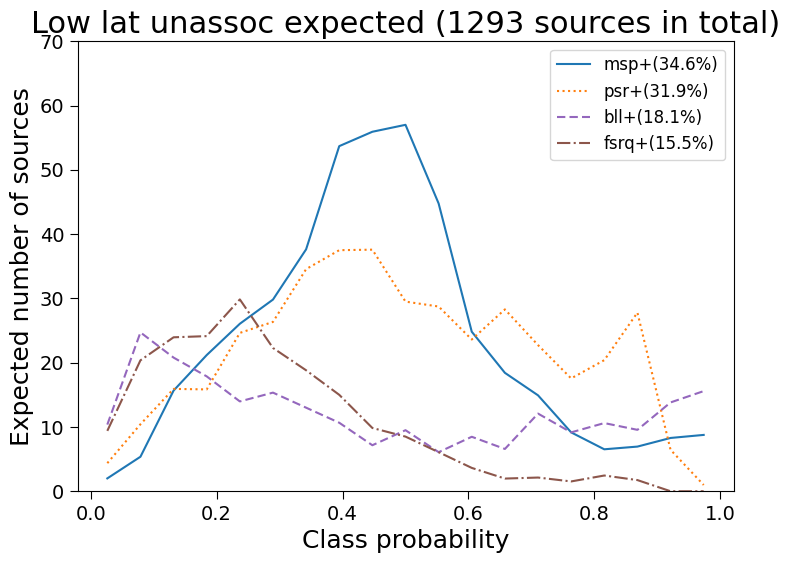

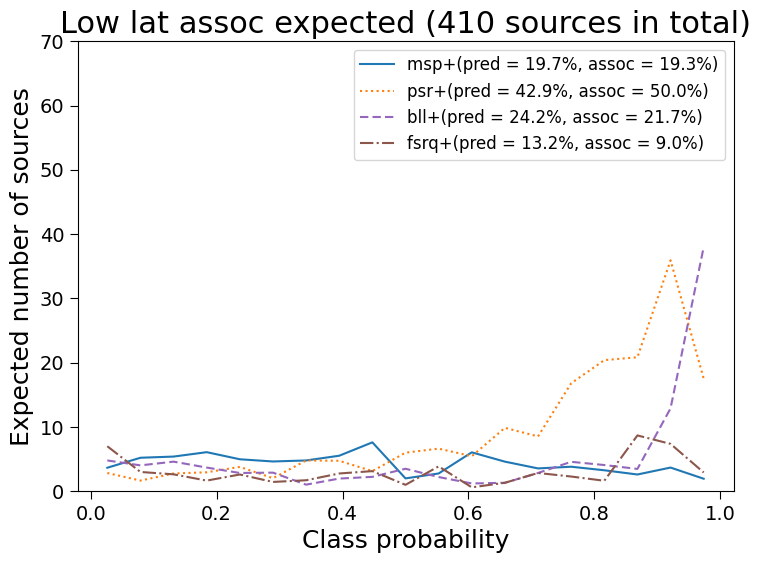

In [14]:
show_fraction = 1
pyplot.figure()
for i in ind_sort:
    cl = sum_df['Class label'].iloc[i]
    if np.sum(pgu[i]) > 2.:
        y, xb = np.histogram(pgu[i], bins=bins)
        if show_fraction:
            label = cl + '(%.1f%%)' % (psum[i]/ngu*100)
        else:
            label = cl + '(%.1f)' % psum[i]
        pyplot.plot(xc, xc * y, ls=lss_dict[cl], c=c_dict[cl], label=label)

pyplot.legend()
pyplot.ylim(0, 70)
pyplot.xlabel('Class probability')
pyplot.ylabel('Expected number of sources')
pyplot.title('%s unassoc expected (%i sources in total)' % (ROI_name, ngu))

if save_plots:
    fn = '%s/mclass_%s_unas_expected_%s.pdf' % (plots_folder, ROI_fn_str, descr_str)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    if save_png:
        fn = fn.replace('.pdf', '.png')
        pyplot.savefig(fn, metadata=fig_meta)

pyplot.figure()
for i in ind_sort:
    cl = sum_df['Class label'].iloc[i]
    if 1:
        cls = sum_df['Physical classes'].iloc[i].split(', ')
        amask = util.get_cl_mask(cls, cat_df, cname=class_name) & hmask
        na_cl = sum(amask)
    y, xb = np.histogram(pga[i], bins=bins)
    if show_fraction:
        label = cl + '(pred = %.1f%%, assoc = %.1f%%)' % (psuma[i]/nga*100., na_cl/nga*100.)
    else:
        label = cl + '(pred = %.1f, assoc = %i)' % (psuma[i], na_cl)
    pyplot.plot(xc, xc * y, ls=lss_dict[cl], c=c_dict[cl], label=label)

pyplot.legend()
pyplot.ylim(0, 70)
pyplot.xlabel('Class probability')
pyplot.ylabel('Expected number of sources')
pyplot.title('%s assoc expected (%i sources in total)' % (ROI_name, nga))

if save_plots:
    fn = '%s/mclass_%s_assoc_expected_%s.pdf' % (plots_folder, ROI_fn_str, descr_str)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    if save_png:
        fn = fn.replace('.pdf', '.png')
        pyplot.savefig(fn, metadata=fig_meta)
